In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt


In [23]:
ad = {1:'a', 2:'b'}

for key in ad:
    print('key', key)


key 1
key 2


In [ ]:
def plot_allele_species_percentage(file_path, target_strains, min_percentage=0.5):
    """
    Plots allele species percentage from a CSV and annotates bars that include target strains.
    
    Parameters:
        file_path (str): Path to the input CSV file with allele info.
        target_strains (list): List of strain names to mark on the plot.
        min_percentage (float): Minimum species percentage to include in the plot.
    """
    # Load data
    df = pd.read_csv(file_path)
    df_filtered = df[df['species_percentage'] > min_percentage]

    # Set up the plot
    plt.figure(figsize=(10, 6))
    barplot = sns.barplot(
        x="allele_name", 
        y="species_percentage", 
        hue="allele_name", 
        data=df_filtered, 
        palette="Blues_d",
        width=0.4,
        dodge=False,
        legend=False
    )

    plt.xticks(rotation=45, ha='right')
    plt.xlabel("Allele Name")
    plt.ylabel("Species Percentage (%)")
    plt.title(f"Alleles with Species Percentage > {min_percentage}%")
    plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter())

    # Annotate bars with strain names
    for index, row in df_filtered.iterrows():
        for strain in target_strains:
            if pd.notna(row['strain_names']) and strain in row['strain_names']:
                bar_index = df_filtered.index.get_loc(index)
                bar = barplot.patches[bar_index]
                height = bar.get_height()
                x = bar.get_x() + bar.get_width() / 2
                plt.text(x, height + 1, strain, ha='center', va='bottom', fontsize=10, color='red', rotation=90)

    plt.tight_layout()
    plt.show()

In [20]:
from collections import defaultdict

def plot_allele_species_percentage(file_path, target_strains, min_percentage=0.5):
    """
    Plots allele species percentage and annotates bars containing target strains,
    stacking strain names to avoid overlapping.
    
    Parameters:
        file_path (str): CSV file path.
        target_strains (list): List of strain names to annotate.
        min_percentage (float): Filter threshold for plotting.
    """
    df = pd.read_csv(file_path)
    df_filtered = df[df['species_percentage'] > min_percentage]

    plt.figure(figsize=(10, 6))
    barplot = sns.barplot(
        x="allele_name",
        y="species_percentage",
        hue="allele_name",
        data=df_filtered,
        palette="Blues_d",
        width=0.4,
        dodge=False,
        legend=False
    )

    plt.xticks(rotation=45, ha='right')
    plt.xlabel("Allele Name")
    plt.ylabel("Species Percentage (%)")
    plt.title(f"Alleles with Species Percentage > {min_percentage}%")
    plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter())

    # Track number of annotations per bar
    annotation_count = defaultdict(int)

    for index, row in df_filtered.iterrows():
        if pd.isna(row['strain_names']):
            continue

        strain_hits = [s for s in target_strains if s in row['strain_names']]
        if not strain_hits:
            continue

        bar_index = df_filtered.index.get_loc(index)
        bar = barplot.patches[bar_index]
        base_x = bar.get_x() + bar.get_width() / 2
        base_y = bar.get_height()

        for i, strain in enumerate(strain_hits):
            offset = 2 + annotation_count[row['allele_name']] * 7
            plt.text(
                base_x, base_y + offset, strain,
                ha='center', va='bottom', fontsize=9, color='black', rotation=90
            )
            annotation_count[row['allele_name']] += 1

    plt.tight_layout()
    plt.show()

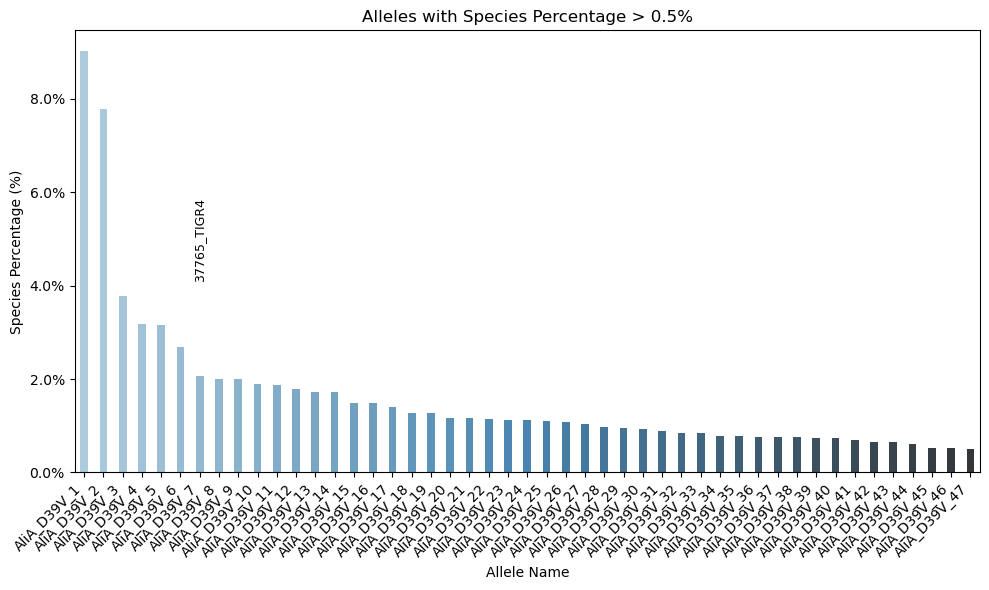

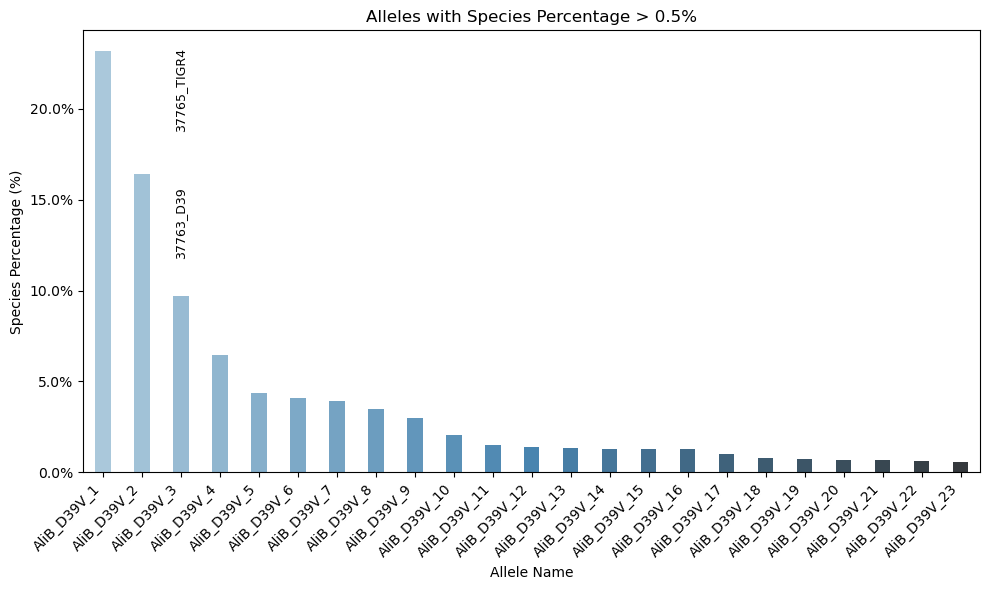

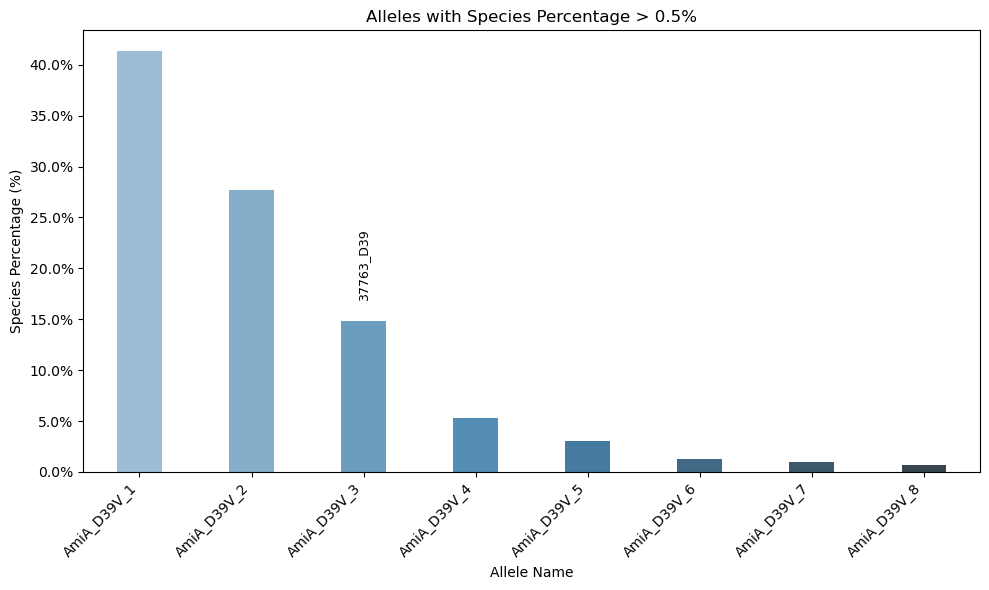

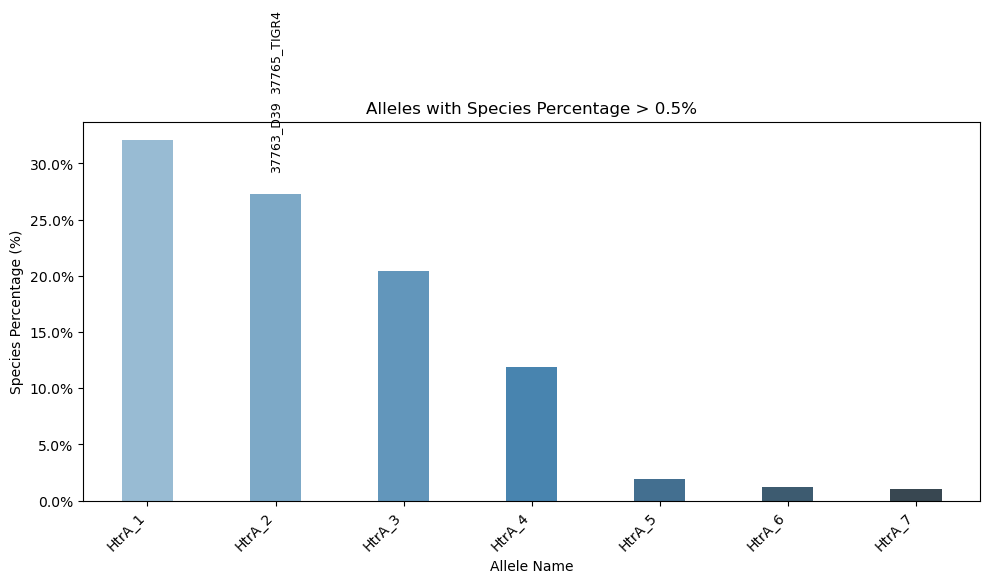

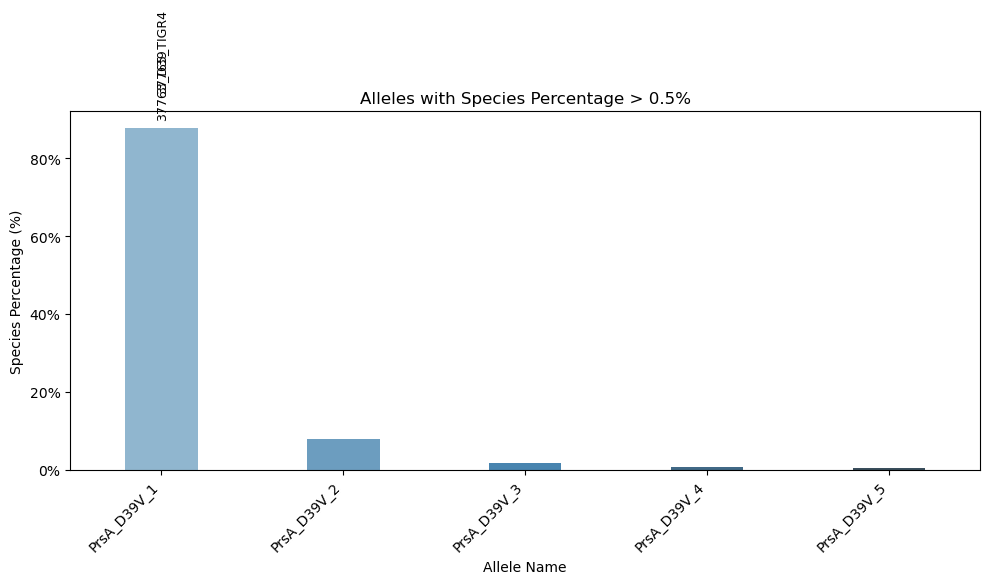

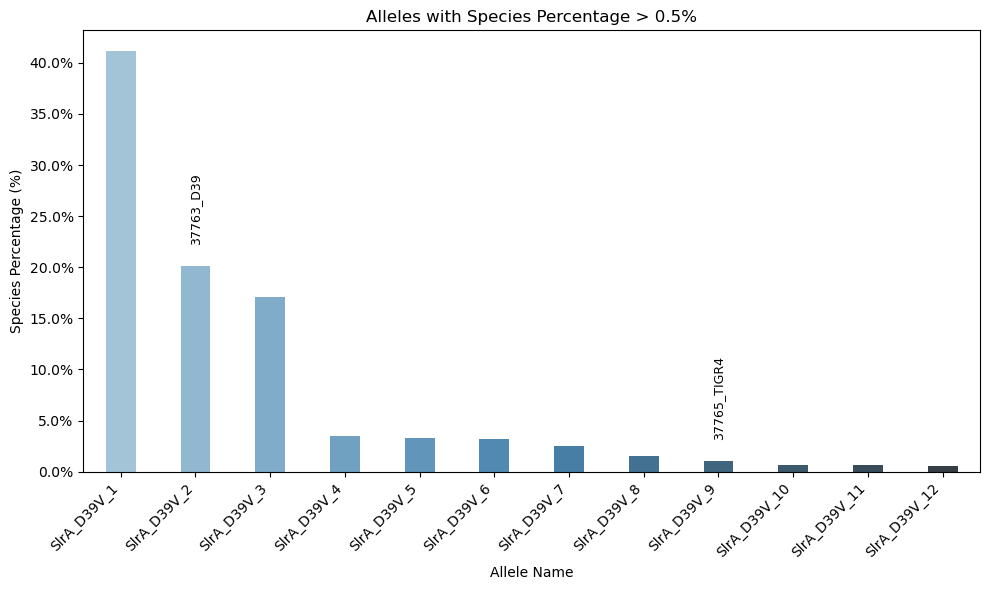

In [21]:
path_list = ['/home/xinruoz/Document/Hiller/surface_chaperones/output/allele_info/AliA_D39V/query_reference/allele_info_with_strain_name.csv',
             '/home/xinruoz/Document/Hiller/surface_chaperones/output/allele_info/AliB_D39V/query_reference/allele_info_with_strain_name.csv',
             '/home/xinruoz/Document/Hiller/surface_chaperones/output/allele_info/AmiA_D39V/query_reference/allele_info_with_strain_name.csv',
             '/home/xinruoz/Document/Hiller/surface_chaperones/output/allele_info/HtrA/query_reference/allele_info_with_strain_name.csv',
             '/home/xinruoz/Document/Hiller/surface_chaperones/output/allele_info/PrsA_D39V/query_reference/allele_info_with_strain_name.csv',
             '/home/xinruoz/Document/Hiller/surface_chaperones/output/allele_info/SlrA_D39V/query_reference/allele_info_with_strain_name.csv',
             ]
for file_path in path_list:
    plot_allele_species_percentage(file_path=file_path, target_strains=['37763_D39', '37765_TIGR4'])

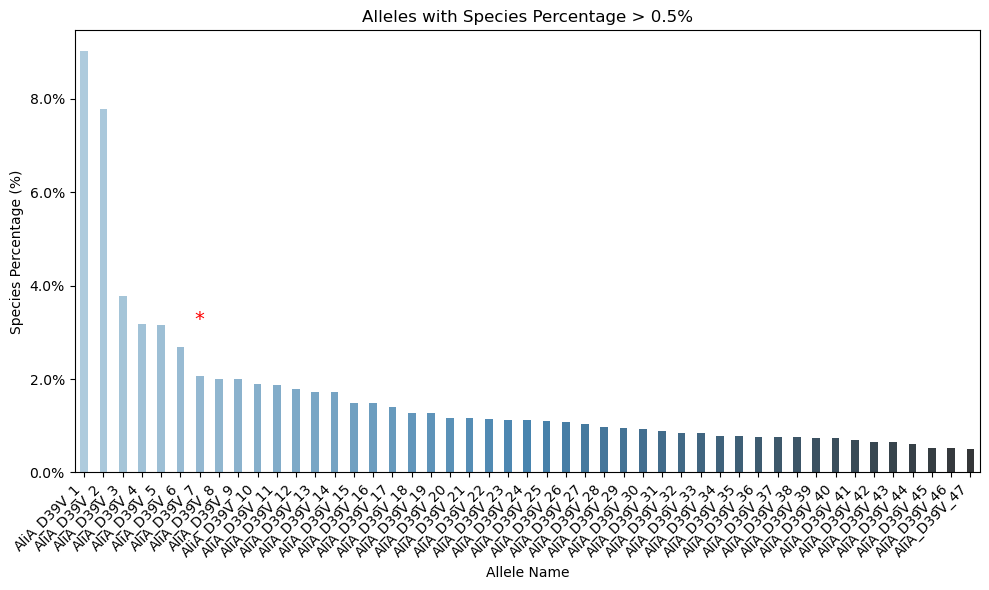

In [ ]:
file_path = "/home/xinruoz/Document/Hiller/surface_chaperones/output/allele_info/AliA_D39V/query_reference/allele_info_with_strain_name.csv"
df = pd.read_csv(file_path)
# Filter
df_filtered = df[df['species_percentage'] > 0.5]

# Find alleles that contain specific strains
target_strains = ['37763_D39', '37765_TIGR4']
marked_alleles = []

for strain in target_strains:
    matches = df_filtered[df_filtered['strain_names'].str.contains(strain, na=False)]
    marked_alleles.extend(matches['allele_name'].tolist())

# Plot
plt.figure(figsize=(10, 6))
barplot = sns.barplot(
    x="allele_name", 
    y="species_percentage", 
    hue="allele_name", 
    data=df_filtered, 
    palette="Blues_d",
    width=0.4,
    dodge=False,
    legend=False
)

# Rotate labels
plt.xticks(rotation=45, ha='right')
plt.xlabel("Allele Name")
plt.ylabel("Species Percentage (%)")
plt.title("Alleles with Species Percentage > 0.5%")
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter())

# Add markers
for index, row in df_filtered.iterrows():
    if row['allele_name'] in marked_alleles:
        bar_index = df_filtered.index.get_loc(index)
        bar = barplot.patches[bar_index]
        height = bar.get_height()
        x = bar.get_x() + bar.get_width() / 2
        plt.text(x, height + 1, '*', ha='center', va='bottom', fontsize=14, color='red')

plt.tight_layout()
plt.show()